# Notebook 03 · Pronósticos externos, enero de 2023 a julio de 2026

**Pregunta:** ¿qué se pronostica en cada mes, usando solo su pasado?

**Entradas:** panel auditado y configuración congelada de 02. **Salida de modelado:** una tabla de pronósticos
por target, distrito, estrategia y mes. **Salidas de revisión:** controles de cobertura, ejemplos y dos figuras.
Aquí se mantienen los hiperparámetros y se verifican las predicciones; las comparaciones de desempeño se realizan en 04.

Ruta: **configuración → cortes temporales → pronósticos verificados → caso real → cierre**.
En modo `revisar` se carga la corrida incluida tras verificar su cadena y cobertura, sin entrenar ni reemplazarla.
En modo `reentrenar` se calculan Δz, Ridge y referencias, reutilizando los niveles v2 según la ruta descrita en README.md.
Los gráficos se generan aquí a partir de `forecasts` y el panel auditado. Usa la misma `CARPETA_RESULTADOS` que en 02.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import drive
except ImportError:
    PROJECT_DIR = Path.cwd()  # En local, abrir desde la carpeta SIDPOL_Notebooks.
else:
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/Asesorias/Forecasting/SIDPOL_Notebooks')

MODO = 'revisar'  # 'revisar' no entrena. 'reentrenar' exige otra carpeta y el entorno fijado.
CARPETA_RESULTADOS = 'resultados'
sys.path.insert(0, str(PROJECT_DIR))
import sidpol as sp
import sidpol_figuras as sf

sp.require(MODO in ['revisar', 'reentrenar'], 'MODO debe ser revisar o reentrenar.')
P, ENV, panel, Q, districts = sp.setup(PROJECT_DIR, CARPETA_RESULTADOS)
if MODO == 'reentrenar':
    sp.require(CARPETA_RESULTADOS != 'resultados', 'Use otra carpeta para no sobrescribir la corrida entregada.')
    sp.require_training_environment(ENV)

print(f'Modo: {MODO} | Carpeta: {P.root / CARPETA_RESULTADOS}')
print('Entorno de esta ejecución:', ENV)
registros_figuras = []

Mounted at /content/drive


/content/drive/MyDrive/Asesorias/Forecasting/SIDPOL_Notebooks/sidpol.py:97: UserWarning: Versiones distintas de requirements_modelado.txt (esperada, actual): {'numpy': ('2.1.3', '2.4.6')}. En modo revisar se verifican archivos guardados y se registra este entorno. No se está reproduciendo el entrenamiento. Consulte README.md.
  warnings.warn(f'Versiones distintas de requirements_modelado.txt (esperada, actual): {wrong}. '


Modo: revisar | Carpeta: /content/drive/MyDrive/Asesorias/Forecasting/SIDPOL_Notebooks/resultados
Entorno de esta ejecución: {'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'xgboost': '3.4.1', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0'}


## 1. Configuración que viene de 02

$H_{\mathrm{L}}$ y $H_{\mathrm{G}}$ identifican las configuraciones Local y Global en niveles;
$H_{\mathrm{L5}}$ y $H_{\mathrm{G5}}$, las configuraciones correspondientes a Δz.
En el código se llaman `H_L`, `H_G`, `H_L5` y `H_G5`.

E1 utiliza H_L en ambos modelos; E1b utiliza H_G en Global. E5 y E5b siguen la misma lógica con H_L5 y H_G5.
Compartir hiperparámetros por modelo no iguala la capacidad total de los 43 modelos Locales con la de uno Global.
En esta notebook no se selecciona otra configuración al observar los resultados externos.

In [2]:
config = sp.load_config(P)
sp.check_config_contract(config)
display(sp.selection_table(config['selected']))
print('Hash de configuración:', sp.sha256_file(P.config))

,Estatus,Robo,Hurto
profundidad × árboles · score 2022,,,
Local · niveles (H_L),Principal,2 × 100 · 0.606,2 × 100 · 0.629
Global · niveles (H_G),Sensibilidad,6 × 100 · 0.522,6 × 100 · 0.556
Local · Δz (H_L5),Exploratorio,1 × 25 · 0.513,1 × 25 · 0.524
Global · Δz (H_G5),Exploratorio,4 × 300 · 0.492,2 × 25 · 0.496
Ridge · Δz (α),Exploratorio,α = 100 · 0.542,α = 10 · 0.540
Naïve-1 (solo referencia),Referencia,— · 0.528,— · 0.530


Hash de configuración: bbd0029c48041d9f0de74cf793838b5003250775be907b1efab014cc4e256625


## 2. Ver el rolling-origin en fechas reales

`cutoff` es el último mes permitido en entrenamiento y `forecast_month` el mes que se pronostica.
El horizonte es $h=1$: si se pronostica el mes $t$, el corte corresponde a $t-1$.
La ventana crece un mes en cada paso y se mantiene la configuración elegida en 02.

La tabla se construye desde las fechas del panel y las variables de modelado. Para enero de 2023,
cada distrito y target tiene 60 meses de historia, pero 48 filas útiles después de descartar
los 12 meses iniciales sin `lag_12`. El modelo Global reúne las filas útiles de los 43 distritos.
Un valor observado en un mes externo puede incorporarse al entrenamiento de los meses siguientes,
siempre después de haber sido observado.

In [3]:
features = sp.build_features(panel, districts)
filas_cortes = []
for mes in [sp.EXTERNAL_MONTHS[0], sp.BREAK_DATE, sp.EXTERNAL_MONTHS[-1]]:
    for target in sp.TARGETS:
        entrenamiento = features[(features.target == target) & (features.fecha < mes)]
        prueba = features[(features.target == target) & (features.fecha == mes)]
        cuentas = entrenamiento.groupby('UBIGEO', observed=True).size()
        cutoff = entrenamiento.fecha.max()
        sp.require(cutoff == mes - pd.DateOffset(months=1), 'Corte temporal incorrecto.')
        filas_cortes.append({'target': target, 'forecast_month': mes, 'cutoff': cutoff,
            'filas_utiles_por_distrito_min': cuentas.min(), 'filas_utiles_por_distrito_max': cuentas.max(),
            'filas_global': len(entrenamiento), 'distritos_a_pronosticar': prueba.UBIGEO.nunique()})
tabla_cortes = pd.DataFrame(filas_cortes)
display(tabla_cortes)

,target,forecast_month,cutoff,filas_utiles_por_distrito_min,filas_utiles_por_distrito_max,filas_global,distritos_a_pronosticar
0,ROBO,2023-01-01,2022-12-01,48,48,2064,43
1,HURTO,2023-01-01,2022-12-01,48,48,2064,43
2,ROBO,2024-11-01,2024-10-01,70,70,3010,43
3,HURTO,2024-11-01,2024-10-01,70,70,3010,43
4,ROBO,2026-07-01,2026-06-01,90,90,3870,43
5,HURTO,2026-07-01,2026-06-01,90,90,3870,43


## 3. Leer o generar los pronósticos

La cobertura se comprueba por **claves exactas**, no solo por número de filas. Se verifican los valores observados,
los dos naïve y que cada `cutoff` sea exactamente el mes anterior al mes pronosticado.

La corrida completa tiene **44,290 filas**: 11 estrategias con 3,698 pronósticos cada una
($43$ distritos × $2$ targets × $43$ meses) y Global-42 con 3,612.
El estatus de una estrategia —principal, de sensibilidad, exploratoria o post hoc— no cambia por obtener menor error.

In [4]:
if MODO == 'revisar':
    forecasts = sp.load_forecasts(P)
    print('Corrida registrada cargada; no se entrena.')
else:
    sp.require(not P.forecasts.exists(), 'Ya existe una corrida en esa carpeta. Use revisar o una carpeta nueva.')
    forecasts = sp.forecast_all(P, panel, districts, config)
    sp.save_forecasts(P, ENV, forecasts)

sp.check_forecasts(forecasts, panel, districts, config['e3_excluded_ubigeo'])
sp.require((forecasts.cutoff == forecasts.forecast_month - pd.DateOffset(months=1)).all(), 'Cutoff inválido.')
sp.require(len(forecasts) == 44290, 'La corrida completa debe tener 44,290 filas.')
display(sp.forecast_summary(forecasts))

Corrida registrada cargada; no se entrena.


,Estatus,Pronósticos,Origen
Local · niveles,Principal,3698,corrida v2 (verificada)
Global · niveles (H_L),Principal,3698,corrida v2 (verificada)
Global · niveles (H_G),Sensibilidad,3698,corrida v2 (verificada)
Global · 42 distritos,Sensibilidad,3612,corrida v2 (verificada)
Naïve-1,Referencia,3698,calculado en la corrida registrada
Naïve estacional,Referencia,3698,calculado en la corrida registrada
Local · Δz,Exploratorio,3698,calculado en la corrida registrada
Global · Δz (H_L5),Exploratorio,3698,calculado en la corrida registrada
Global · Δz (H_G5),Exploratorio,3698,calculado en la corrida registrada
Ridge · Δz,Exploratorio,3698,calculado en la corrida registrada


## 4. Auditar un pronóstico y sus referencias

Para cada target, se ordenan los distritos por su volumen mediano de **2018–2022** y se elige el que ocupa
la posición central. La regla ilustra un caso sin escogerlo por el resultado del modelo; no representa por sí solo a Lima.

Naïve-1 repite el mes anterior y naïve estacional el mismo mes del año anterior:

$$
\widehat{y}^{\mathrm{naive1}}_{d,t}=y_{d,t-1},
\qquad
\widehat{y}^{\mathrm{estacional}}_{d,t}=y_{d,t-12}.
$$

Las igualdades se comprueban a continuación con los observados del panel.

In [5]:
casos = sp.example_districts(panel)
display(casos)
target_ejemplo = 'ROBO'
ubigeo_ejemplo = str(casos.loc[casos.target == target_ejemplo, 'UBIGEO'].iloc[0])
mes_ejemplo = sp.EXTERNAL_MONTHS[0]
caso = forecasts[(forecasts.target == target_ejemplo) & (forecasts.UBIGEO == ubigeo_ejemplo)
                 & (forecasts.forecast_month == mes_ejemplo)].copy()
display(caso[['strategy', 'cutoff', 'forecast_month', 'y_true', 'y_pred']])
serie_panel = panel[(panel.target == target_ejemplo) & (panel.UBIGEO.astype(str) == ubigeo_ejemplo)].set_index('fecha').y
for strategy, lag in [('naive1', 1), ('naive_seasonal', 12)]:
    esperado = serie_panel.loc[mes_ejemplo - pd.DateOffset(months=lag)]
    obtenido = caso.loc[caso.strategy == strategy, 'y_pred'].iloc[0]
    sp.require(obtenido == esperado, f'{strategy} no coincide con el rezago.')
    print(f'{strategy}: {obtenido:g} = observado de {(mes_ejemplo - pd.DateOffset(months=lag)):%Y-%m}')

,target,UBIGEO,DIST_HECHO,mediana_volumen_previo,fecha_limite_volumen
0,ROBO,150121,PUEBLO LIBRE,34.0,2023-01-01
1,HURTO,150116,LINCE,71.0,2023-01-01


,strategy,cutoff,forecast_month,y_true,y_pred
1826,global_42,2022-12-01,2023-01-01,36.0,38.078648
5481,global_HG,2022-12-01,2023-01-01,36.0,37.916840
9179,global_HL,2022-12-01,2023-01-01,36.0,36.420300
12877,global_dz_HG,2022-12-01,2023-01-01,36.0,34.892634
16575,global_dz_HL,2022-12-01,2023-01-01,36.0,40.716286
20273,local_HL,2022-12-01,2023-01-01,36.0,36.918411
23971,local_dz_HL,2022-12-01,2023-01-01,36.0,40.538828
27669,naive1,2022-12-01,2023-01-01,36.0,43.000000
31367,naive_seasonal,2022-12-01,2023-01-01,36.0,33.000000
35065,ridge_dz,2022-12-01,2023-01-01,36.0,36.027141


naive1: 43 = observado de 2022-12
naive_seasonal: 33 = observado de 2022-01


## 5. Observados frente a pronósticos de esos distritos

Cada gráfico contiene los **43 meses externos reales**. Las líneas de los modelos son predicciones a un paso,
no ajustes sobre entrenamiento ni proyecciones de 43 meses realizadas de una sola vez.
La marca de noviembre de 2024 señala el cambio de registro documentado; no identifica un efecto causal.

Se muestran Local y Global en niveles con H_L, junto con naïve-1, para leer el contraste principal.
Las demás estrategias permanecen en la tabla completa y se comparan en 04.

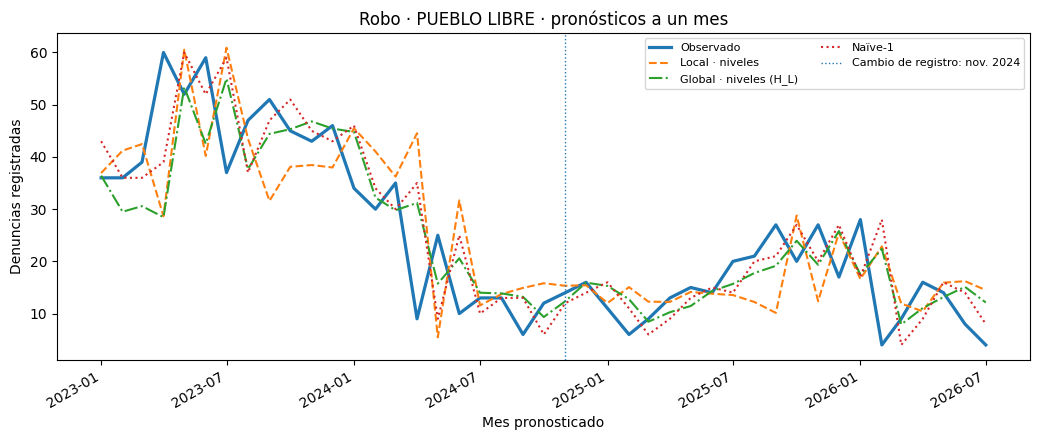

Distrito 150121, elegido por volumen previo, no por error. Fuente: forecasts de esta ejecución. Ilustración distrital, no estimación de desempeño general.
Datos de esta figura: serie_robo_datos.csv


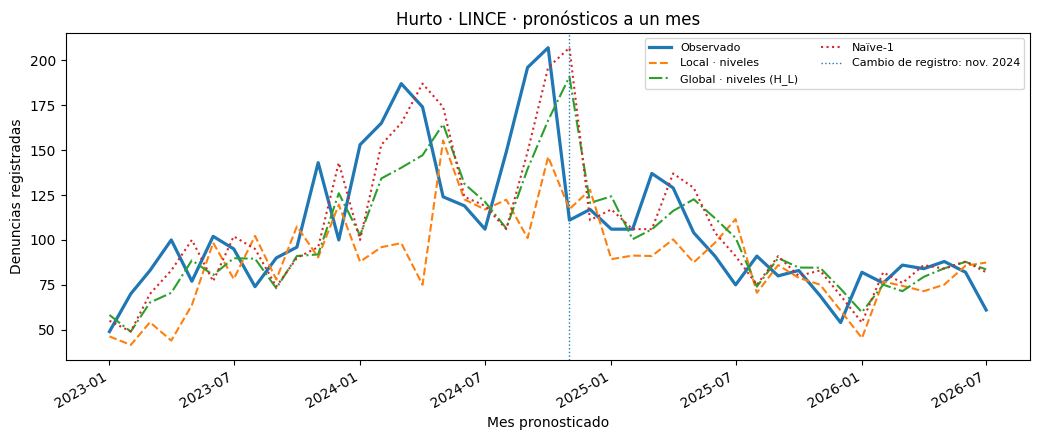

Distrito 150116, elegido por volumen previo, no por error. Fuente: forecasts de esta ejecución. Ilustración distrital, no estimación de desempeño general.
Datos de esta figura: serie_hurto_datos.csv


In [6]:
FIG = P.forecast / 'figuras_notebook'
for registro in casos.itertuples(index=False):
    datos_grafico = forecasts[(forecasts.target == registro.target)
        & (forecasts.UBIGEO == str(registro.UBIGEO))
        & forecasts.strategy.isin(['local_HL', 'global_HL', 'naive1'])].copy()
    observados = (datos_grafico[['forecast_month', 'y_true']].drop_duplicates().sort_values('forecast_month'))
    sp.require(len(observados) == 43 and datos_grafico.groupby('strategy').size().eq(43).all(), 'Serie incompleta.')
    fig, ax = plt.subplots(figsize=(10.5, 4.5))
    ax.plot(observados.forecast_month, observados.y_true, linewidth=2.3, label='Observado')
    for strategy, estilo in [('local_HL', '--'), ('global_HL', '-.'), ('naive1', ':')]:
        serie_modelo = datos_grafico[datos_grafico.strategy == strategy].sort_values('forecast_month')
        ax.plot(serie_modelo.forecast_month, serie_modelo.y_pred, linestyle=estilo, label=sp.LABEL_ES[strategy])
    ax.axvline(sp.BREAK_DATE, linestyle=':', linewidth=1, label='Cambio de registro: nov. 2024')
    ax.set(title=f'{sp.ES[registro.target]} · {registro.DIST_HECHO} · pronósticos a un mes',
           xlabel='Mes pronosticado', ylabel='Denuncias registradas')
    ax.legend(fontsize=8, ncol=2)
    fig.autofmt_xdate()
    registros_figuras.append(sf.guardar_y_mostrar(fig, datos_grafico, FIG,
        f'serie_{registro.target.lower()}',
        f'Distrito {registro.UBIGEO}, elegido por volumen previo, no por error. Fuente: forecasts de esta ejecución. '
        'Ilustración distrital, no estimación de desempeño general.', '03', '5. Series observadas y pronosticadas'))

## 6. Cierre y transición a resultados

Los gráficos describen las predicciones de los distritos elegidos; no determinan superioridad estadística general.
Notebook 04 utilizará **los mismos pronósticos** para calcular errores por distrito y comparaciones pareadas.

**Para explicar:** elige una fila del ejemplo y justifica el corte temporal, los dos naïve y la configuración del modelo.
Cada figura se genera con el código visible de esta notebook. Después abre 04 con el mismo `PROJECT_DIR` y
la misma `CARPETA_RESULTADOS`; en 04 conserva `MODO = 'revisar'`.

In [7]:
sp.write_csv(FIG / 'cortes_temporales_reales.csv', tabla_cortes)
sp.write_csv(FIG / 'distritos_ejemplo.csv', casos)
sp.write_csv(FIG / 'primer_pronostico_ejemplo.csv', caso)
display(sf.guardar_indice(registros_figuras, FIG))
sp.save_manifest(FIG, ENV, [f for f in FIG.iterdir() if f.is_file()],
    mode=MODO, training_performed=(MODO == 'reentrenar'),
    forecasts_sha256=sp.sha256_file(P.forecasts), config_sha256=sp.sha256_file(P.config),
    code_sha256={n: sp.sha256_file(PROJECT_DIR / n) for n in ['sidpol.py', 'sidpol_figuras.py']})
print('READY_FOR_NOTEBOOK_04 — cobertura verificada y gráficos generados desde los pronósticos.')

,notebook,seccion,figura,datos,filas
0,03,5. Series observadas y pronosticadas,serie_robo.png,serie_robo_datos.csv,129
1,03,5. Series observadas y pronosticadas,serie_hurto.png,serie_hurto_datos.csv,129


READY_FOR_NOTEBOOK_04 — cobertura verificada y gráficos generados desde los pronósticos.
